# Temporal Analysis with CDO

## Analyzing Climate Data Across Time

CDO provides powerful operators for temporal aggregation and analysis. This notebook demonstrates how to compute monthly, seasonal, and annual means, calculate climatologies, and detect anomalies.

### Learning Objectives:
- Compute temporal means at various scales (monthly, seasonal, annual)
- Calculate climatologies and anomalies
- Apply running means for smoothing
- Visualize temporal patterns in climate data

In [1]:
import subprocess
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import os
# CDO is installed as cdo.cmd on Windows; use the right executable name.
CDO = 'cdo.cmd' if os.name == 'nt' else 'cdo'


In [2]:
# Use a real monthly temperature time series from NCEP/DOE Reanalysis-2
data_dir = '../data'
output_dir = '../output'
os.makedirs(data_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

real_file = os.path.join('..', 'datasets', 'tas_sample.nc')
ds_real = xr.open_dataset(real_file)

# Area-weight the global field (weights must be labelled by latitude)
lat_w = xr.DataArray(np.cos(np.deg2rad(ds_real.lat.values)),
                     dims=('lat',), coords={'lat': ds_real.lat})
temperature = ds_real.tas.weighted(lat_w).mean(dim=('lat', 'lon')) - 273.15
time = ds_real.time.values

ds = xr.Dataset(
    {'temperature': ('time', temperature.values,
                     {'units': 'degC', 'long_name': 'Global mean monthly temperature'})},
    coords={'time': time}
)
ds.attrs = {'title': 'Real global mean monthly temperature',
            'source': 'NCEP/DOE Reanalysis-2 (tas_sample.nc)'}

ts_file = os.path.join(data_dir, 'real_monthly_temp.nc')
ds.to_netcdf(ts_file)
print(f'Using real dataset: {real_file}')
print(f'Time range: {time[0]} to {time[-1]}')
print(f'Number of months: {len(time)}')
print(f'Temperature range: {temperature.min():.1f} to {temperature.max():.1f} degC')

Using real dataset: ..\datasets\tas_sample.nc
Time range: 1980-01-01T00:00:00.000000000 to 2010-12-01T00:00:00.000000000
Number of months: 372
Temperature range: 12.7 to 16.4 degC


In [3]:
# Compute monthly means using cdo monmean
subprocess.run([CDO, 'monmean', ts_file, os.path.join(output_dir, 'monthly_mean.nc')], capture_output=True, text=True)

ds_monthly = xr.open_dataset(os.path.join(output_dir, 'monthly_mean.nc'))
print('Monthly means:')
print(ds_monthly)
print(f'\nNumber of months: {len(ds_monthly.time)}')

Monthly means:
<xarray.Dataset> Size: 12kB
Dimensions:      (time: 372, bnds: 2)
Coordinates:
  * time         (time) datetime64[ns] 3kB 1980-01-01 1980-02-01 ... 2010-12-01
Dimensions without coordinates: bnds
Data variables:
    time_bnds    (time, bnds) datetime64[ns] 6kB ...
    temperature  (time) float64 3kB ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real global mean monthly temperature
    frequency:    mon
    history:      Sun Nov 22 18:49:01 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...

Number of months: 372


In [4]:
# Compute seasonal means using cdo seasmean
# DJF = Dec-Jan-Feb, MAM = Mar-Apr-May, JJA = Jun-Jul-Aug, SON = Sep-Oct-Nov
subprocess.run([CDO, 'seasmean', ts_file, os.path.join(output_dir, 'seasonal_mean.nc')], capture_output=True, text=True)

ds_seasonal = xr.open_dataset(os.path.join(output_dir, 'seasonal_mean.nc'))
print('Seasonal means:')
print(ds_seasonal)
print(f'\nNumber of seasons: {len(ds_seasonal.time)}')

Seasonal means:
<xarray.Dataset> Size: 4kB
Dimensions:      (time: 125, bnds: 2)
Coordinates:
  * time         (time) datetime64[ns] 1kB 1980-01-16T12:00:00 ... 2010-12-01
Dimensions without coordinates: bnds
Data variables:
    time_bnds    (time, bnds) datetime64[ns] 2kB ...
    temperature  (time) float64 1kB ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real global mean monthly temperature
    history:      Sun Nov 22 18:49:02 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...

Number of seasons: 125


In [5]:
# Compute annual means using cdo yearmean
subprocess.run([CDO, 'yearmean', ts_file, os.path.join(output_dir, 'annual_mean.nc')], capture_output=True, text=True)

ds_annual = xr.open_dataset(os.path.join(output_dir, 'annual_mean.nc'))
print('Annual means:')
print(ds_annual)
print(f'\nNumber of years: {len(ds_annual.time)}')

Annual means:
<xarray.Dataset> Size: 992B
Dimensions:      (time: 31, bnds: 2)
Coordinates:
  * time         (time) datetime64[ns] 248B 1980-06-16 1981-06-16 ... 2010-06-16
Dimensions without coordinates: bnds
Data variables:
    time_bnds    (time, bnds) datetime64[ns] 496B ...
    temperature  (time) float64 248B ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real global mean monthly temperature
    frequency:    year
    history:      Sun Nov 22 18:49:03 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...

Number of years: 31


In [6]:
# Calculate climatology using cdo ymonmean
# ymonmean computes the mean for each month across all years
subprocess.run([CDO, 'ymonmean', ts_file, os.path.join(output_dir, 'climatology.nc')], capture_output=True, text=True)

ds_clim = xr.open_dataset(os.path.join(output_dir, 'climatology.nc'))
print('Monthly climatology (mean for each calendar month):')
print(ds_clim)
print(f'\nClimatological values:')
for i, temp in enumerate(ds_clim.temperature.values):
    month = i + 1
    print(f'  Month {month:2d}: {temp:.2f} degC')

Monthly climatology (mean for each calendar month):
<xarray.Dataset> Size: 384B
Dimensions:      (time: 12, bnds: 2)
Coordinates:
  * time         (time) datetime64[ns] 96B 2010-01-01 2010-02-01 ... 2010-12-01
Dimensions without coordinates: bnds
Data variables:
    time_bnds    (time, bnds) datetime64[ns] 192B ...
    temperature  (time) float64 96B ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real global mean monthly temperature
    history:      Sun Nov 22 18:49:04 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...

Climatological values:
  Month  1: 12.69 degC
  Month  2: 12.91 degC
  Month  3: 13.54 degC
  Month  4: 14.46 degC
  Month  5: 15.35 degC
  Month  6: 16.05 degC
  Month  7: 16.36 degC
  Month  8: 16.20 degC
  Month  9: 15.49 degC
  Month 10: 14.45 deg

In [7]:
# Compute anomalies (deviation from climatology)
# First compute monthly means, then subtract the monthly climatology
# Use cdo sub to subtract: cdo sub monthly_monmean.nc ymonmean.nc anomalies.nc

monthly_file = os.path.join(output_dir, 'monthly_mean.nc')
clim_file = os.path.join(output_dir, 'climatology.nc')
anom_file = os.path.join(output_dir, 'anomalies.nc')

# ymonmean produces 12 timesteps; we need to expand it to match monthly data
# Alternative: use cdo ymonsub to directly compute anomalies
subprocess.run([CDO, 'ymonsub', monthly_file, clim_file, anom_file], capture_output=True, text=True)

ds_anom = xr.open_dataset(anom_file)
print('Temperature anomalies (degC):')
print(ds_anom)
print(f'Anomaly range: {ds_anom.temperature.values.min():.2f} to {ds_anom.temperature.values.max():.2f} degC')

Temperature anomalies (degC):
<xarray.Dataset> Size: 12kB
Dimensions:      (time: 372, bnds: 2)
Coordinates:
  * time         (time) datetime64[ns] 3kB 1980-01-01 1980-02-01 ... 2010-12-01
Dimensions without coordinates: bnds
Data variables:
    time_bnds    (time, bnds) datetime64[ns] 6kB ...
    temperature  (time) float64 3kB ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real global mean monthly temperature
    frequency:    mon
    history:      Sun Nov 22 18:49:06 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...
Anomaly range: -0.02 to 0.02 degC


In [8]:
# Running means with cdo runmean
# Smooth the monthly data with a 12-month running mean
subprocess.run([CDO, 'runmean,12', ts_file, os.path.join(output_dir, 'runmean_12month.nc')], capture_output=True, text=True)

# Also compute a 36-month running mean for comparison
subprocess.run([CDO, 'runmean,36', ts_file, os.path.join(output_dir, 'runmean_36month.nc')], capture_output=True, text=True)

ds_run30 = xr.open_dataset(os.path.join(output_dir, 'runmean_12month.nc'))
ds_run90 = xr.open_dataset(os.path.join(output_dir, 'runmean_36month.nc'))
print(f'12-month running mean: {len(ds_run30.time)} timesteps')
print(f'36-month running mean: {len(ds_run90.time)} timesteps')

12-month running mean: 361 timesteps
36-month running mean: 337 timesteps


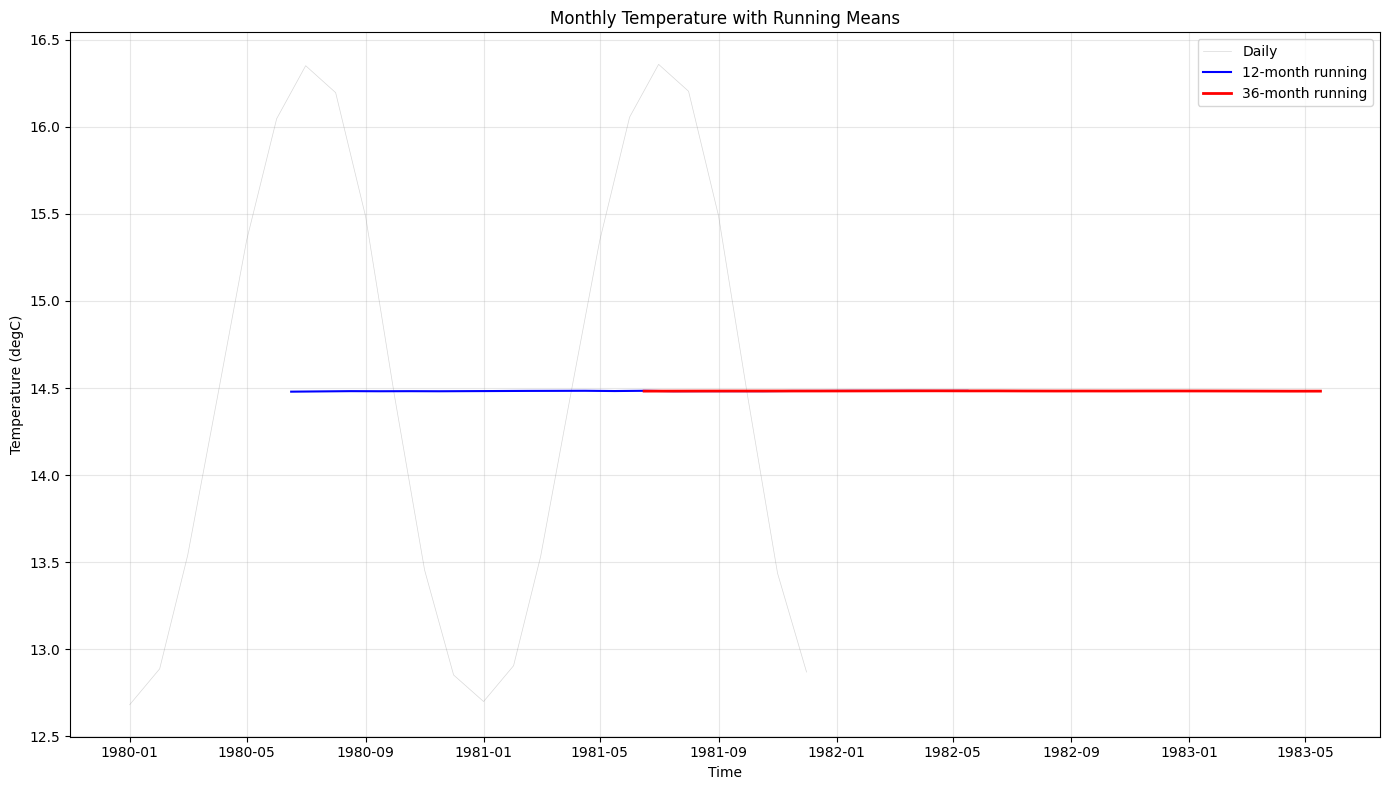

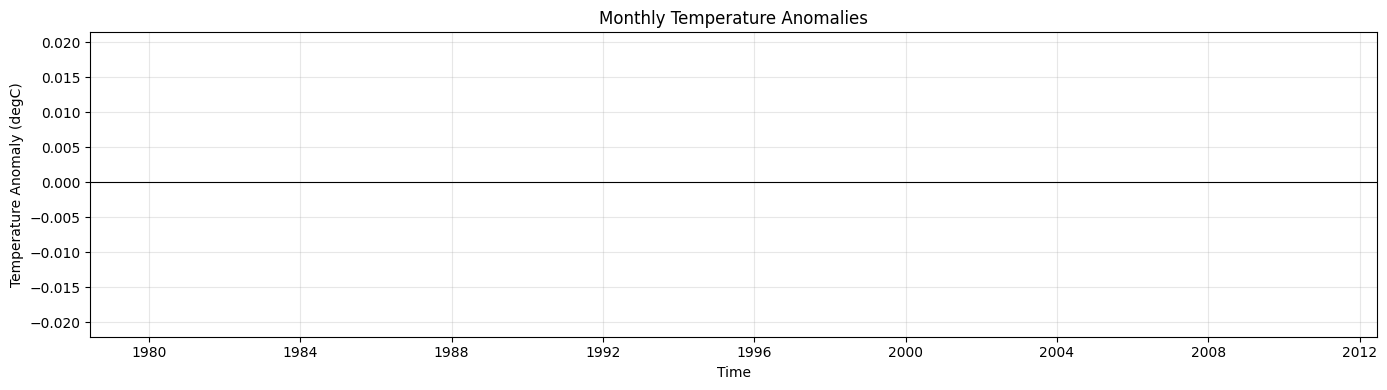

In [9]:
# Visualize with matplotlib
plt.figure(figsize=(14, 8))

# Plot 2 years of data for clarity
start = 0
end = 24  # 2 years of monthly data

# Raw daily data
plt.plot(ds.time[start:end], ds.temperature[start:end],
         alpha=0.3, color='gray', linewidth=0.5, label='Daily')

# 30-day running mean
plt.plot(ds_run30.time[start:end], ds_run30.temperature[start:end],
         color='blue', linewidth=1.5, label='12-month running')

# 90-day running mean
plt.plot(ds_run90.time[start:end], ds_run90.temperature[start:end],
         color='red', linewidth=2, label='36-month running')

plt.xlabel('Time')
plt.ylabel('Temperature (degC)')
plt.title('Monthly Temperature with Running Means')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Anomaly plot
plt.figure(figsize=(14, 4))
plt.bar(ds_anom.time.values, ds_anom.temperature.values,
        width=25, color='red' if ds_anom.temperature.values[-1] > 0 else 'blue', alpha=0.6)
plt.axhline(y=0, color='black', linewidth=0.8)
plt.xlabel('Time')
plt.ylabel('Temperature Anomaly (degC)')
plt.title('Monthly Temperature Anomalies')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Exercises

1. Compute the 10th and 90th percentiles of the daily temperature data using `cdo timpctl`
2. Select only summer months (JJA) using `cdo selseason`
3. Compute the number of frost days per year (days with T < 0 degC) using `cdo ecacf` or custom logic
4. Compute the trend in annual mean temperature using `cdo trend`
5. Create a harmonic analysis using `cdo harmonic` to extract the annual cycle

In [10]:
# Exercise 4: Compute temperature trend
subprocess.run([CDO, 'trend', annual_file if 'annual_file' in dir() else os.path.join(output_dir, 'annual_mean.nc'),
               os.path.join(output_dir, 'trend_intercept.nc'),
               os.path.join(output_dir, 'trend_slope.nc')],
              capture_output=True, text=True)

ds_slope = xr.open_dataset(os.path.join(output_dir, 'trend_slope.nc'))
ds_intercept = xr.open_dataset(os.path.join(output_dir, 'trend_intercept.nc'))

print('Trend analysis:')
print(f'  Slope: {ds_slope.temperature.values.ravel()[0]:.4f} degC/year')
print(f'  Intercept: {ds_intercept.temperature.values.ravel()[0]:.2f} degC')
total_change = ds_slope.temperature.values.ravel()[0] * (len(ds_annual.time) - 1)
print(f'  Total change over period: {total_change:.2f} degC')

Trend analysis:
  Slope: 0.0001 degC/year
  Intercept: 14.48 degC
  Total change over period: 0.00 degC


In [11]:
# Exercise 1: Percentiles using cdo timpctl
# CDO needs explicit minimum and maximum fields as histogram bounds.
min_file = os.path.join(output_dir, 'ts_min.nc')
max_file = os.path.join(output_dir, 'ts_max.nc')
pctl_file = os.path.join(output_dir, 'percentiles.nc')

subprocess.run([CDO, 'timmin', ts_file, min_file], capture_output=True, text=True)
subprocess.run([CDO, 'timmax', ts_file, max_file], capture_output=True, text=True)
subprocess.run([CDO, 'timpctl,30', ts_file, min_file, max_file, pctl_file],
               capture_output=True, text=True)

ds_pctl = xr.open_dataset(pctl_file)
print('Percentile analysis:')
if hasattr(ds_pctl, 'temperature'):
    print(f'  30th percentile: {ds_pctl.temperature.values.ravel()[0]:.2f} degC')
    print(f'  Temperature range: {ds_pctl.temperature.values.min():.2f} to '
          f'{ds_pctl.temperature.values.max():.2f} degC')

Percentile analysis:
  30th percentile: 13.45 degC
  Temperature range: 13.45 to 13.45 degC
